In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [64]:
def K_hat(sig_i, sig_e, n):
    j = np.arange(n)
    d = np.minimum(j, n-j)

    K = np.exp(-d**2 / (2*sig_e**2)) - (sig_e/sig_i)*np.exp(-d**2 / (2*sig_i**2))
    
    return np.fft.rfft(K) 

def ring_cortex(n, Khat, t_end, dt):
    steps = int(t_end/dt)
    w = 0.01 * rng.standard_normal(n)
    w_all = np.zeros((steps+1, n))
    w_all[0, :] = w
    for i in range(1,steps+1):
        conv = np.fft.irfft(Khat * np.fft.rfft(w), n=n)
        w = np.clip(w + dt * conv, -1, 1)
        w_all[i, :] = w
    return w, w_all

def k_star(sig_i, sig_e):
    return np.sqrt(4*np.log(sig_i/sig_e) / (sig_i**2 - sig_e**2))

In [30]:
K2 = K_hat(2,1,200)
w_last2, w_all2 = ring_cortex(200, K2, 40, .02)

K3 = K_hat(3,1,200)
w_last3, w_all3 = ring_cortex(200, K3, 40, .02)

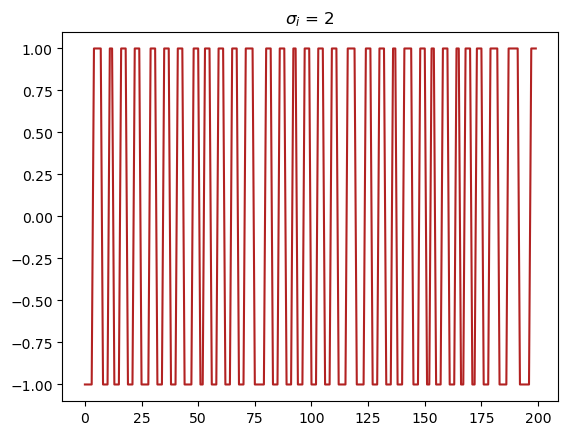

In [100]:
plt.plot(np.arange(200), w_last2, color = "firebrick")
plt.title(r"$\sigma_i$ = 2")
plt.savefig("ocularstrip1", dpi = 300, bbox_inches = "tight")
plt.show()

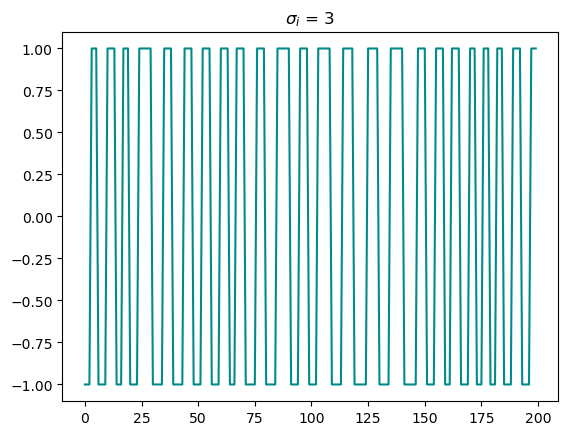

In [98]:
plt.plot(np.arange(200), w_last3, color = "darkcyan")
plt.title(r"$\sigma_i$ = 3")
plt.savefig("ocularstrip2", dpi = 300, bbox_inches = "tight")
plt.show()

In [68]:
stripes2 = np.zeros(20)
stripes3 = np.zeros(20)

for j in range(20):
    w_last2, _ = ring_cortex(200, K2, 40, .02)
    w_last3, _ = ring_cortex(200, K3, 40, .02)

    stripes2[j] = 400/sum([w_last2[i] * w_last2[i-1] < 0 for i in range(1,200)])
    stripes3[j] = 400/sum([w_last3[i] * w_last3[i-1] < 0 for i in range(1,200)])    


In [78]:
# stripe period
np.mean(stripes2), np.mean(stripes3)

(6.532656832335436, 8.129016660705727)

In [66]:
# theoretical stripe period
2*np.pi/k_star(2,1), 2*np.pi/k_star(3,1)

(6.5357851842730055, 8.477594506537999)

In [72]:
# largest fourier mode
n_best2 = np.argmax(K2.real[1:]) + 1
n_best3 = np.argmax(K3.real[1:]) + 1

200/n_best2, 200/n_best3

(6.451612903225806, 8.333333333333334)